# Milestone 6: Predictive Model, Customer Churn
**Kenya retail data platform** · Which active customers will stop buying in the next 90 days?

**Business question.** A store manager can only phone or message a limited number of customers. Which ones should they contact first to keep them from lapsing?

**Plan**
1. Define churn precisely and build a dataset of customer snapshots over time.
2. Split by **time** (train on the past, validate on the middle, test on the most recent months). Random splits would leak the future.
3. Set simple **baselines**, then fit a logistic regression and a gradient-boosting model.
4. Evaluate on the untouched test period with metrics that suit an imbalanced yes/no problem.

## Step 1: Importing relevant libraries

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score, confusion_matrix, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
SEED = 42
DATA = "../data/clean"

tx = pd.read_csv(f"{DATA}/transactions.csv", parse_dates=["transaction_date"])
customers = pd.read_csv(f"{DATA}/customers.csv")
print(f"{len(tx):,} lines | {tx.transaction_date.min().date()} to {tx.transaction_date.max().date()}")

250,000 lines | 2022-01-01 to 2025-09-30


## Step 2: Defining Churn and Building the dataset
- Churn is defined at each month-end snapshot as an active customer (someone who purchased within the previous 180 days) making no purchase during the following 90 days. 
- The dataset contains one record per active customer per month, with features calculated only from information available up to the snapshot date to prevent data leakage; walk-in customers and returns are excluded from purchase counts. 
- The model uses behavioural and customer characteristics, including purchase recency, frequency, spending, visit patterns, payment and sales channel preferences, promotion use, returns, loyalty status, age band, and gender.

In [2]:
# One row per invoice for identified customers (walk-ins have no customer_id and cannot be tracked)
sales = tx[(~tx["is_return"]) & tx["customer_id"].notna()]
inv = (sales.groupby("invoice_no")
       .agg(customer_id=("customer_id", "first"), date=("transaction_date", "min"), store_id=("store_id", "first"),
            payment=("payment_method", "first"), channel=("channel", "first"), on_promo=("on_promo", "max"),
            value=("line_total_kes", "sum"), units=("quantity", "sum"))
       .reset_index())
returns = tx[tx["is_return"] & tx["customer_id"].notna()][["customer_id", "transaction_date"]]
print(f"{len(inv):,} invoices from {inv.customer_id.nunique():,} customers")

85,073 invoices from 4,605 customers


In [3]:
# Churn definition 
# Active customers purchased within the previous 180 days.
# A customer churns if they make no purchase in the next 90 days.
# Features use historical data only; the churn label uses future data.
HORIZON, ACTIVE_WINDOW = 90, 180

# Get the latest transaction date to determine the available snapshot period.
DATA_END = inv["date"].max()


def build_snapshot(T):
    # Convert the snapshot date to a pandas datetime value.
    T = pd.Timestamp(T)

    # Keep only purchases and returns recorded on or before the snapshot date.
    past = inv[inv["date"] <= T]
    ret = returns[returns["transaction_date"] <= T]

    # Group historical purchases by customer to calculate behaviour features.
    g = past.groupby("customer_id")

    # Build customer-level features using historical purchase information.
    f = pd.DataFrame({
        "last_date": g["date"].max(),                 # Most recent purchase date
        "first_date": g["date"].min(),                # First recorded purchase date
        "freq_all": g["invoice_no"].count(),          # Total number of purchases
        "monetary_all": g["value"].sum(),             # Total historical spending
        "avg_basket": g["value"].mean(),              # Average purchase value
        "units_per_invoice": g["units"].mean(),       # Average units per purchase
        "n_stores": g["store_id"].nunique(),          # Number of different stores used
        "mpesa_share": g["payment"].apply(lambda s: (s == "M-Pesa").mean()),  # M-Pesa usage share
        "online_share": g["channel"].apply(lambda s: (s == "Online").mean()), # Online purchase share
        "promo_share": g["on_promo"].mean(),          # Share of purchases made on promotion
    })

    # Calculate purchase frequency and spending within selected time windows.
    for d in (30, 90, 180, 365):
        w = past[past["date"] > T - pd.Timedelta(days=d)].groupby("customer_id")
        f[f"freq_{d}d"] = w["invoice_no"].count()

        # Calculate spending for the 90-day and 365-day periods.
        if d in (90, 365):
            f[f"spend_{d}d"] = w["value"].sum()

    # Replace missing frequency and spending values with zero.
    f = f.fillna({c: 0 for c in f.columns if c.startswith(("freq_", "spend_"))})

    # Calculate customer recency and length of relationship.
    f["recency_days"] = (T - f["last_date"]).dt.days
    f["tenure_days"] = (T - f["first_date"]).dt.days

    # Estimate the customer's average time between purchases.
    f["mean_gap_days"] = f["tenure_days"] / (f["freq_all"] - 1).replace(0, np.nan)

    # Compare days since the last purchase with the customer's usual visit gap.
    f["recency_vs_gap"] = f["recency_days"] / f["mean_gap_days"]

    # Compare recent purchase frequency with the average yearly purchase pace.
    f["freq_trend"] = f["freq_90d"] / (f["freq_365d"] / 4).replace(0, np.nan)

    # Count historical returns for each customer.
    f["n_returns"] = ret.groupby("customer_id").size().reindex(f.index).fillna(0)

    # Retain only customers who meet the 180-day active customer definition.
    f = f[f["recency_days"] <= ACTIVE_WINDOW].copy()

    # Identify customers who made at least one purchase during the next 90 days.
    fut = inv[
        (inv["date"] > T) &
        (inv["date"] <= T + pd.Timedelta(days=HORIZON))
    ]["customer_id"].unique()

    # Assign churn = 1 if the customer does not appear in the future purchase data.
    f["churn"] = (~f.index.isin(fut)).astype(int)

    # Record the snapshot date for each customer observation.
    f["snapshot"] = T

    # Remove intermediate date columns and return one row per customer.
    return f.drop(columns=["last_date", "first_date"]).reset_index()


# Generate month-end snapshot dates with enough future data for churn labelling.
snap_dates = pd.date_range(
    "2022-12-31",
    DATA_END - pd.Timedelta(days=HORIZON),
    freq="ME"
)

# Build and combine the customer-level datasets for all snapshot dates.
data = pd.concat([build_snapshot(T) for T in snap_dates], ignore_index=True)

# Add customer demographic and loyalty information.
data = data.merge(
    customers[["customer_id", "loyalty_member", "age", "age_band", "gender", "preferred_payment"]],
    on="customer_id",
    how="left"
)

# Convert loyalty membership into an integer variable.
data["loyalty_member"] = data["loyalty_member"].astype(int)

# Display the number of snapshots, customer observations, and overall churn rate.
print(
    f"{len(snap_dates)} monthly snapshots, "
    f"{len(data):,} customer-snapshot rows, "
    f"overall churn rate {data.churn.mean():.1%}"
)

# Preview the completed customer churn dataset.
data.head()

31 monthly snapshots, 85,229 customer-snapshot rows, overall churn rate 33.1%


,customer_id,freq_all,monetary_all,avg_basket,units_per_invoice,n_stores,mpesa_share,online_share,promo_share,freq_30d,...,recency_vs_gap,freq_trend,n_returns,churn,snapshot,loyalty_member,age,age_band,gender,preferred_payment
0,C0001,12,"17,255.500","1,437.958",4.167,12,1.000,0.000,0.083,2.000,...,0.246,2.000,0.000,1,2022-12-31,0,26.000,25-34,Male,M-Pesa
1,C0003,5,"13,271.000","2,654.200",6.000,1,0.800,0.000,0.000,2.000,...,0.035,2.400,0.000,0,2022-12-31,1,40.000,35-44,Male,M-Pesa
2,C0005,2,"4,987.500","2,493.750",8.000,2,0.000,0.000,0.000,0.000,...,0.452,2.000,0.000,1,2022-12-31,0,38.000,35-44,Male,Cash
3,C0009,13,"27,943.700","2,149.515",7.308,5,0.923,0.077,0.154,1.000,...,0.261,1.538,0.000,0,2022-12-31,0,35.000,35-44,Male,M-Pesa
4,C0011,6,"14,748.750","2,458.125",6.833,2,0.333,0.000,0.167,0.000,...,0.717,2.000,0.000,0,2022-12-31,1,NaN,Unknown,Male,Cash


## Step 3: Time-aware train / validation / test split
| Split | Snapshots | Purpose |
|---|---|---|
| Train | Dec 2022 to Jun 2024 | learn patterns |
| Validation | Oct to Dec 2024 | choose the model and the decision threshold |
| Test | Apr to Jun 2025 | final, one-time evaluation |

The gaps between splits are deliberate. The last training label window ends 28 Sep 2024, before validation begins, and the last validation label window ends 31 Mar 2025, before the test begins, so no split "sees" outcomes that belong to another.

In [4]:
# Time-aware split
# The model must predict the FUTURE from the PAST. Each split ends its 90-day label window
# before the next split begins, so no label information leaks across splits.
TRAIN_END, VAL_START, VAL_END, TEST_START = "2024-06-30", "2024-10-31", "2024-12-31", "2025-04-30"
train = data[data.snapshot <= TRAIN_END]
val   = data[(data.snapshot >= VAL_START) & (data.snapshot <= VAL_END)]
test  = data[data.snapshot >= TEST_START]
for name, d in (("train", train), ("validation", val), ("test", test)):
    print(f"{name:11s} snapshots {d.snapshot.min().date()} to {d.snapshot.max().date()} | rows {len(d):6,} | churn rate {d.churn.mean():.1%}")
print("\nLast training label window ends:", (pd.Timestamp(TRAIN_END) + pd.Timedelta(days=HORIZON)).date(), "(before validation starts)")
print("Last validation label window ends:", (pd.Timestamp(VAL_END) + pd.Timedelta(days=HORIZON)).date(), "(before test starts)")

NUM = ["recency_days", "tenure_days", "freq_all", "freq_30d", "freq_90d", "freq_180d", "freq_365d", "monetary_all", "spend_90d", "spend_365d",
       "avg_basket", "units_per_invoice", "n_stores", "mpesa_share", "online_share", "promo_share", "mean_gap_days", "recency_vs_gap",
       "freq_trend", "n_returns", "loyalty_member", "age"]
CAT = ["age_band", "gender", "preferred_payment"]
FEATURES = NUM + CAT
X_tr, y_tr = train[FEATURES], train["churn"]; X_va, y_va = val[FEATURES], val["churn"]; X_te, y_te = test[FEATURES], test["churn"]

train       snapshots 2022-12-31 to 2024-06-30 | rows 52,168 | churn rate 33.5%
validation  snapshots 2024-10-31 to 2024-12-31 | rows  8,301 | churn rate 32.0%
test        snapshots 2025-04-30 to 2025-06-30 | rows  8,156 | churn rate 31.0%

Last training label window ends: 2024-09-28 (before validation starts)
Last validation label window ends: 2025-03-31 (before test starts)


## Step 4: Baselines

A model is only useful if it performs better than a simple alternative. I use three reference approaches:

1. **Constant-probability baseline:** Assign every customer the overall churn rate observed in the training data. This provides a simple reference for evaluating predicted probabilities.
2. **Always-churn baseline:** Classify every customer as likely to churn. This provides a simple reference for classification performance.
3. **Recency rule:** Classify a customer as likely to churn if they have not made a purchase for 60 days or more. This represents a practical rule that a store manager could apply without a predictive model.

In [5]:
# Baselines 
# B1: Assign every customer the average churn probability from the training data.
# B2: Use days since the last purchase as a simple business-based churn indicator.

prevalence = y_tr.mean()

print(
    f"Baseline 1 (constant probability): assign the training churn rate "
    f"({prevalence:.1%}) to every customer -> ROC-AUC 0.50 by construction"
)

print(
    f"Baseline 2 (recency rule): score = days since last purchase | "
    f"validation ROC-AUC = {roc_auc_score(y_va, X_va.recency_days):.3f}, "
    f"PR-AUC = {average_precision_score(y_va, X_va.recency_days):.3f}"
)

print(
    f"  Rule 'churn if no purchase for 60+ days': "
    f"precision = {precision_score(y_va, X_va.recency_days >= 60):.3f}, "
    f"recall = {recall_score(y_va, X_va.recency_days >= 60):.3f}, "
    f"F1 = {f1_score(y_va, X_va.recency_days >= 60):.3f}"
)

print(f"  PR-AUC of a random ranking = validation churn rate = {y_va.mean():.3f}")

Baseline 1 (constant probability): assign the training churn rate (33.5%) to every customer -> ROC-AUC 0.50 by construction
Baseline 2 (recency rule): score = days since last purchase | validation ROC-AUC = 0.691, PR-AUC = 0.499
  Rule 'churn if no purchase for 60+ days': precision = 0.506, recall = 0.493, F1 = 0.500
  PR-AUC of a random ranking = validation churn rate = 0.320


## Step 5: Models and validation
Two models: **logistic regression** (simple, interpretable, standardised inputs) and **gradient boosting** (captures non-linear patterns and interactions). Both are compared on the validation period only.

In [6]:
# Models 
pre_lr = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
                            ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
logit = make_pipeline(pre_lr, LogisticRegression(max_iter=2000, C=0.5, random_state=SEED))

pre_gb = ColumnTransformer([("num", "passthrough", NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
gboost = make_pipeline(pre_gb, HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300,
                                                              l2_regularization=1.0, random_state=SEED))
models = {"Logistic regression": logit, "Gradient boosting": gboost}
rows = []
for name, mdl in models.items():
    mdl.fit(X_tr, y_tr)
    p = mdl.predict_proba(X_va)[:, 1]
    rows.append({"model": name, "val ROC-AUC": roc_auc_score(y_va, p), "val PR-AUC": average_precision_score(y_va, p), "val Brier": brier_score_loss(y_va, p)})
rows.insert(0, {"model": "Baseline: recency rule", "val ROC-AUC": roc_auc_score(y_va, X_va.recency_days),
                "val PR-AUC": average_precision_score(y_va, X_va.recency_days), "val Brier": np.nan})
val_table = pd.DataFrame(rows).set_index("model"); val_table

,val ROC-AUC,val PR-AUC,val Brier
model,,,
Baseline: recency rule,0.691,0.499,NaN
Logistic regression,0.771,0.572,0.176
Gradient boosting,0.784,0.600,0.171


- Both models clearly beat the recency rule on validation (ROC-AUC 0.77 to 0.78 vs 0.69), and gradient boosting is slightly ahead on every metric, including the Brier score, which measures how good the predicted probabilities are (lower is better).

In [7]:
# Choose each model's decision threshold on VALIDATION data only (maximise F1), then freeze it for the test set.
# (Tuning both models the same way keeps the comparison fair.)
THRESHES = {}
for name, mdl in models.items():
    p_v = mdl.predict_proba(X_va)[:, 1]
    prec, rec, thr = precision_recall_curve(y_va, p_v)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    THRESHES[name] = float(thr[np.argmax(f1s)])
    print(f"{name:20s} threshold = {THRESHES[name]:.3f} | validation F1 = {f1s.max():.3f}")
best_name = val_table.drop("Baseline: recency rule")["val PR-AUC"].idxmax()
best, THRESH = models[best_name], THRESHES[best_name]
print(f"\nSelected model (highest validation PR-AUC): {best_name}")

Logistic regression  threshold = 0.258 | validation F1 = 0.611
Gradient boosting    threshold = 0.287 | validation F1 = 0.622

Selected model (highest validation PR-AUC): Gradient boosting


## Step 6: Final evaluation on the test period
The test snapshots (Apr to Jun 2025) were not used for any choice so far.

In [8]:
# Final evaluation on the untouched test period (Apr-Jun 2025 snapshots) 
def evaluate(name, p, y, thresh):
    pred = (p >= thresh).astype(int)
    return {"model": name, "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "precision": precision_score(y, pred), "recall": recall_score(y, pred), "F1": f1_score(y, pred)}

rec_score = X_te.recency_days / X_te.recency_days.max()
rule_pred = (X_te.recency_days >= 60).astype(int)
test_rows = [{"model": "Baseline: always classify as churn", "ROC-AUC": 0.5, "PR-AUC": y_te.mean(),
              "precision": y_te.mean(), "recall": 1.0, "F1": 2 * y_te.mean() / (1 + y_te.mean())},
             {"model": "Baseline: recency >= 60 days", "ROC-AUC": roc_auc_score(y_te, X_te.recency_days),
              "PR-AUC": average_precision_score(y_te, X_te.recency_days), "precision": precision_score(y_te, rule_pred),
              "recall": recall_score(y_te, rule_pred), "F1": f1_score(y_te, rule_pred)}]
probs_te = {}
for name, mdl in models.items():
    probs_te[name] = mdl.predict_proba(X_te)[:, 1]
    thr_m = THRESHES[name]
    test_rows.append(evaluate(name + (f" (threshold {thr_m:.2f})"), probs_te[name], y_te, thr_m))
test_table = pd.DataFrame(test_rows).set_index("model"); test_table

,ROC-AUC,PR-AUC,precision,recall,F1
model,,,,,
Baseline: always classify as churn,0.500,0.310,0.310,1.000,0.474
Baseline: recency >= 60 days,0.722,0.538,0.517,0.587,0.550
Logistic regression (threshold 0.26),0.807,0.625,0.489,0.856,0.623
Gradient boosting (threshold 0.29),0.812,0.632,0.499,0.855,0.630


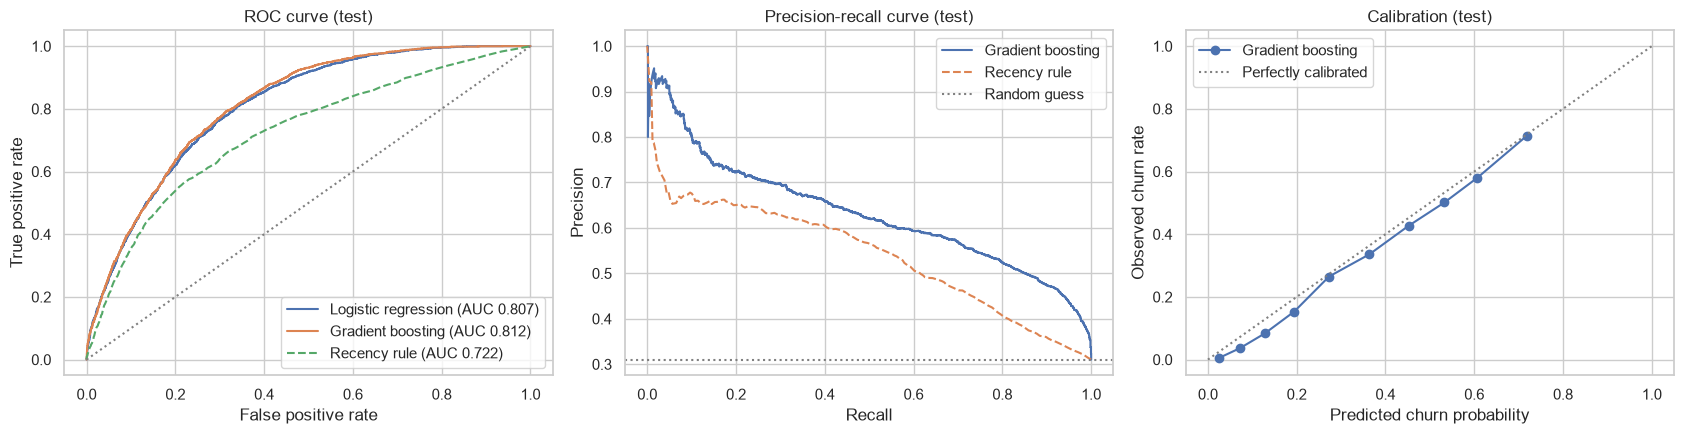

In [9]:
# Model evaluation plots 

# Select the predicted churn probabilities from the best-performing model.
p_te = probs_te[best_name]

# Create three plots to evaluate model performance on the test dataset.
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))


# 1. ROC CURVE: Compare how well each model distinguishes churners from non-churners.
for name, p in probs_te.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    ax[0].plot(
        fpr, tpr,
        label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})"
    )

# Add the recency-based business rule as a reference.
fpr, tpr, _ = roc_curve(y_te, X_te.recency_days)
ax[0].plot(
    fpr, tpr, "--",
    label=f"Recency rule (AUC {roc_auc_score(y_te, X_te.recency_days):.3f})"
)

# Add the random-classification reference line and label the axes.
ax[0].plot([0, 1], [0, 1], ":", color="grey")
ax[0].set_title("ROC curve (test)")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].legend()


# 2. PRECISION-RECALL CURVE: Examine the balance between precision and recall.
# Use the best-performing model's predicted probabilities.
pr, rc, _ = precision_recall_curve(y_te, p_te)
ax[1].plot(rc, pr, label=best_name)

# Compare the model with the recency-based business rule.
pr2, rc2, _ = precision_recall_curve(y_te, X_te.recency_days)
ax[1].plot(rc2, pr2, "--", label="Recency rule")

# Add the churn rate as the reference level for a random ranking.
ax[1].axhline(y_te.mean(), color="grey", ls=":", label="Random guess")
ax[1].set_title("Precision-recall curve (test)")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].legend()


# 3. CALIBRATION CURVE: Check whether predicted probabilities match actual churn rates.
# Group predictions into 10 bins and compare predicted and observed churn rates.
frac, mean_pred = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
ax[2].plot(mean_pred, frac, "o-", label=best_name)

# Add the reference line representing perfect probability calibration.
ax[2].plot(
    [0, 1], [0, 1], ":",
    color="grey",
    label="Perfectly calibrated"
)

ax[2].set_title("Calibration (test)")
ax[2].set_xlabel("Predicted churn probability")
ax[2].set_ylabel("Observed churn rate")
ax[2].legend()


# Adjust spacing and display all three evaluation plots.
plt.tight_layout()
plt.show()

### Test-Set Evaluation: Confusion Matrix and Churn Risk Decile Analysis

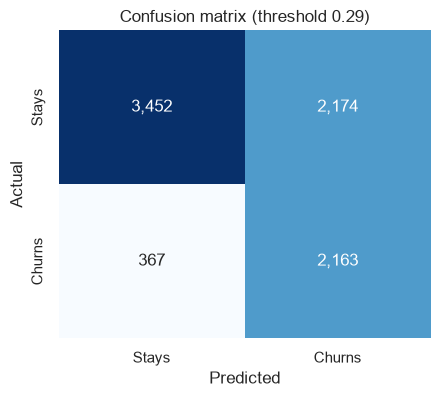

Caught 2,163 of 2,530 churners (recall 85.5%); 2,174 loyal customers flagged by mistake (false positive rate 38.6%).


,customers,churn_rate,lift,cum_share_of_churners
decile,,,,
1,816,0.714,2.303,0.230
2,816,0.581,1.873,0.418
3,815,0.501,1.614,0.579
4,816,0.426,1.375,0.717
5,815,0.336,1.084,0.825
6,816,0.265,0.853,0.910
7,815,0.153,0.494,0.960
8,816,0.083,0.269,0.987
9,815,0.037,0.119,0.998


In [10]:
pred_te = (p_te >= THRESH).astype(int)
cm = confusion_matrix(y_te, pred_te)
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax, xticklabels=["Stays", "Churns"], yticklabels=["Stays", "Churns"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix (threshold {THRESH:.2f})"); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp:,} of {tp+fn:,} churners (recall {tp/(tp+fn):.1%}); {fp:,} loyal customers flagged by mistake (false positive rate {fp/(fp+tn):.1%}).")

# Lift by decile: if the retention team can only contact the top 10-30% riskiest customers, how many churners do they reach?
lift = pd.DataFrame({"p": p_te, "y": y_te.to_numpy()}).sort_values("p", ascending=False).reset_index(drop=True)
lift["decile"] = pd.qcut(lift.index, 10, labels=range(1, 11))
dec = lift.groupby("decile").agg(customers=("y", "size"), churn_rate=("y", "mean")).assign(lift=lambda d: d.churn_rate / y_te.mean())
dec["cum_share_of_churners"] = (dec.churn_rate * dec.customers).cumsum() / lift.y.sum()
display(dec)

## Step 7: What drives the predictions?

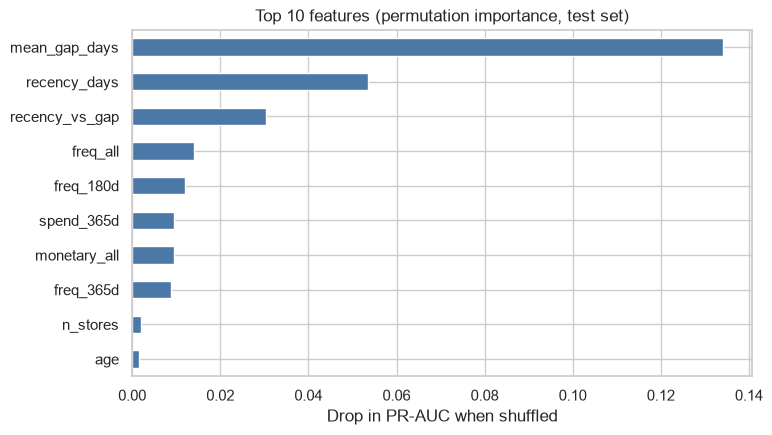

mean_gap_days    0.134
recency_days     0.054
recency_vs_gap   0.030
freq_all         0.014
freq_180d        0.012
spend_365d       0.010
monetary_all     0.009
freq_365d        0.009
n_stores         0.002
age              0.001


In [11]:
# What drives the predictions? Permutation importance on the test set: drop in PR-AUC when a feature is shuffled.
pi = permutation_importance(best, X_te, y_te, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 4.5)); imp[::-1].plot(kind="barh", color="#4C78A8", ax=ax)
ax.set_xlabel("Drop in PR-AUC when shuffled"); ax.set_title("Top 10 features (permutation importance, test set)"); plt.show()
print(imp.round(4).to_string())

The most important feature by far is **`mean_gap_days`**, how long a customer typically goes between purchases. Next come **recency** and **`recency_vs_gap`** (how overdue the customer is compared with their own rhythm). In plain terms: customers with long gaps between visits are naturally at risk, and a customer who has gone quiet for longer than their usual rhythm is at higher risk. Demographics (age, gender) and loyalty status add little. That matches the Milestone 5 result that loyalty does not by itself separate customers who stay from those who leave.

## Step 8: What does the model get wrong?

In [12]:
# What does the model get wrong?
err = test.assign(p=p_te, pred=pred_te)
err["outcome"] = np.select([(err.churn == 1) & (err.pred == 1), (err.churn == 0) & (err.pred == 0),
                            (err.churn == 0) & (err.pred == 1), (err.churn == 1) & (err.pred == 0)], ["TP", "TN", "FP", "FN"], default="")
print("Share of each outcome:"); print(err.outcome.value_counts(normalize=True).round(3).to_string())

prof = err.groupby("outcome")[["recency_days", "freq_all", "freq_90d", "avg_basket", "recency_vs_gap", "loyalty_member"]].mean()
display(prof)

# Error rate by segment: is the model worse for some customer groups?
def seg_table(col):
    g = err.groupby(col).apply(lambda d: pd.Series({"customers": len(d), "churn_rate": d.churn.mean(),
                                                    "recall": recall_score(d.churn, d.pred) if d.churn.sum() else np.nan,
                                                    "precision": precision_score(d.churn, d.pred) if d.pred.sum() else np.nan}))
    return g
err["frequency_band"] = pd.cut(err.freq_all, [0, 3, 8, 20, 10_000], labels=["1-3 visits", "4-8", "9-20", "21+"])
display(seg_table("loyalty_member")); display(seg_table("frequency_band")); display(seg_table("age_band"))

Share of each outcome:
outcome
TN   0.423
FP   0.267
TP   0.265
FN   0.045


,recency_days,freq_all,freq_90d,avg_basket,recency_vs_gap,loyalty_member
outcome,,,,,,
FN,32.490,21.376,2.264,"2,343.235",0.807,0.346
FP,71.742,11.503,0.941,"2,303.851",0.876,0.327
TN,20.866,37.147,3.889,"2,337.380",0.672,0.418
TP,89.479,9.407,0.622,"2,338.926",1.084,0.328


,customers,churn_rate,recall,precision
loyalty_member,,,,
0,"5,166.000",0.328,0.858,0.498
1,"2,990.000",0.280,0.848,0.500


,customers,churn_rate,recall,precision
frequency_band,,,,
1-3 visits,997.000,0.607,0.987,0.638
4-8,"1,605.000",0.498,0.950,0.548
9-20,"2,389.000",0.322,0.817,0.390
21+,"3,165.000",0.113,0.501,0.442


,customers,churn_rate,recall,precision
age_band,,,,
18-24,823.000,0.286,0.817,0.505
25-34,"1,399.000",0.337,0.858,0.506
35-44,"1,414.000",0.300,0.858,0.519
45-54,"1,377.000",0.325,0.872,0.521
55-64,"1,469.000",0.316,0.873,0.489
65+,"1,517.000",0.293,0.840,0.468
Unknown,157.000,0.280,0.773,0.415


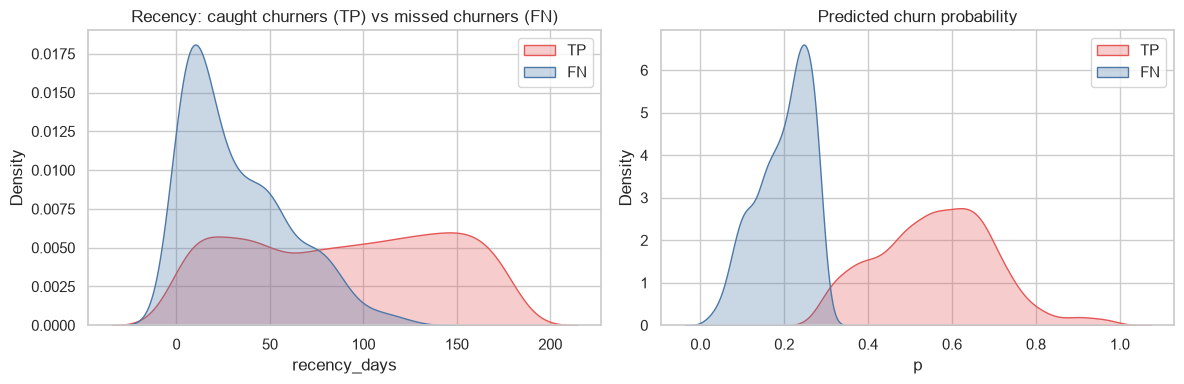

In [13]:
# The churners the model MISSES (false negatives) vs those it catches: the missed ones look like active customers
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for o, c in (("TP", "#E45756"), ("FN", "#4C78A8")):
    sns.kdeplot(err.loc[err.outcome == o, "recency_days"], ax=ax[0], label=o, color=c, fill=True, alpha=0.3)
    sns.kdeplot(err.loc[err.outcome == o, "p"], ax=ax[1], label=o, color=c, fill=True, alpha=0.3)
ax[0].set_title("Recency: caught churners (TP) vs missed churners (FN)"); ax[0].legend()
ax[1].set_title("Predicted churn probability"); ax[1].legend(); plt.tight_layout(); plt.show()

Findings
1. Missed churners: False negatives account for 4.5% of rows. They are often established, frequent customers who stop buying suddenly. Recall drops to 50% for customers with 21+ visits, compared with 95–99% for those with 1–8 visits.

2. False alarms: False positives are mainly occasional customers with longer purchasing gaps. Precision is lowest at 39% among customers with 9–20 visits.

3. Segment consistency: Performance is similar across loyalty groups and age bands. The small unknown-age group performs slightly worse.

4. Temporal stability: Monthly ROC-AUC remains between 0.80 and 0.82, indicating consistent performance across the test period.

In [14]:
# Does performance hold up month by month in the test period? (a model that only works in one month is fragile)
rows = []
for T, d in err.groupby("snapshot"):
    rows.append({"snapshot": T.date(), "customers": len(d), "churn_rate": d.churn.mean(), "ROC-AUC": roc_auc_score(d.churn, d.p),
                 "PR-AUC": average_precision_score(d.churn, d.p), "recall": recall_score(d.churn, d.pred), "precision": precision_score(d.churn, d.pred)})
pd.DataFrame(rows).set_index("snapshot")

,customers,churn_rate,ROC-AUC,PR-AUC,recall,precision
snapshot,,,,,,
2025-04-30,2774,0.329,0.804,0.632,0.843,0.514
2025-05-31,2726,0.306,0.818,0.640,0.862,0.498
2025-06-30,2656,0.295,0.816,0.628,0.861,0.484


## Step 9: Export risk scores for the dashboard
Every currently active customer is scored as of the last day of data (30 Sep 2025). No outcome exists for this date, which is exactly how the model would be used in practice.

In [15]:
# Score every currently active customer AS OF THE LAST DAY OF DATA, for the Power BI "customers at risk" page (Milestone 7).
# No label exists for this date (the future is unknown), which is exactly the real-world use of the model.
now = build_snapshot(DATA_END).drop(columns="churn").merge(customers[["customer_id", "loyalty_member", "age", "age_band", "gender", "preferred_payment"]], on="customer_id", how="left")
now["loyalty_member"] = now["loyalty_member"].astype(int)
scored = now[["customer_id", "snapshot", "recency_days", "freq_all", "monetary_all"]].copy()
scored["churn_probability"] = best.predict_proba(now[FEATURES])[:, 1]
scored["risk_band"] = pd.cut(scored.churn_probability, [0, THRESH, 0.6, 1.0], labels=["Low", "Medium", "High"], include_lowest=True)
scored.sort_values("churn_probability", ascending=False).to_csv(f"{DATA}/customer_churn_scores.csv", index=False)
print(f"Saved {len(scored):,} active customers scored as of {DATA_END.date()} to data/clean/customer_churn_scores.csv")
scored.risk_band.value_counts().to_frame("customers")

Saved 2,608 active customers scored as of 2025-09-30 to data/clean/customer_churn_scores.csv


,customers
risk_band,
Low,1355
Medium,918
High,335
